# <font color="red">Read data</font>

In [1]:
import pandas as pd

data = pd.read_excel("data.xlsx")

data = data[data.Country != "Israel"]



# <font color="red">Explore et analyse data</font>

## <font color="green">general data</font>

In [2]:
# # shape, size
# print("shape:", data.shape)

# # columns
# print(data.columns)

# # types
# print(data.dtypes)

# # info
# print(data.info())

# # duplucated
# print(data.duplicated())



## <font color="green">clean data</font>

In [3]:
import datetime as dt
def clean_na_neg():
    global data
    
    data = data.dropna(subset=["CustomerID"])
    
    data = data[data.Quantity > 0]
    # data["Description"] = data["Description"].fillna("No desc")
    
    print(data.shape) 
    
def convert_types():
    data["CustomerID"]= data["CustomerID"].astype("int64")
    data["InvoiceNo"] = data["InvoiceNo"].astype("str")
    data["StockCode"] = data["StockCode"].astype("str")
    data["Description"] = data["Description"].astype("str")
    data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
    
clean_na_neg()
convert_types()

# print(data.info())  
    
    

(397676, 8)


## <font color="green">RFM</font>

In [4]:
def get_recency():
    # connait le fédality du clients 
    def calculate_date_diff():
        last_date_sale = data.InvoiceDate.max() + dt.timedelta(days=1)
        last_sales_by_client  = data.groupby("CustomerID")["InvoiceDate"].max()
        return (last_date_sale - last_sales_by_client).dt.days


    recency = calculate_date_diff()

    return recency 
    

def get_frequence():
    # connait le nomber de transaction fait par clients
    counts = data["CustomerID"].value_counts()
    return counts
    
def get_montary():
    # connait combien du argent gaspillé 
    max_sales = data.assign(total= data["Quantity"]* data["UnitPrice"]).groupby("CustomerID")["total"].sum()
    return max_sales

recency, frequence, montary = get_recency(), get_frequence(), get_montary()


ids = data.CustomerID.unique()

clients_rfm = {
    "ClientId": [],
    "recency": [],
    "frequence": [],
    "montary": []
}
for i in ids:
    clients_rfm["ClientId"].append(i)
    clients_rfm["recency"].append(recency[i])
    clients_rfm["frequence"].append(frequence[i])
    clients_rfm["montary"].append(montary[i])
    
df_clients_rfm = pd.DataFrame(clients_rfm)    
df_clients_rfm.head()


    

,ClientId,recency,frequence,montary
0,17850,372,297,5391.21
1,13047,32,172,3237.54
2,12583,3,247,7281.38
3,13748,96,28,948.25
4,15100,334,3,876.00


## <font color="green">charts</font>

In [5]:
# import matplotlib.pyplot as plt

# def get_boxplot():
#     recency = df_clients_rfm["recency"]
#     frequence = df_clients_rfm["frequence"]
#     montary = df_clients_rfm["montary"]   
     
#     fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#     axes[0].boxplot(recency)
#     axes[0].set_title("Recency")

#     axes[1].boxplot(frequence)
#     axes[1].set_title("Frequency")

#     axes[2].boxplot(montary)
#     axes[2].set_title("Monetary")

#     plt.tight_layout()
#     plt.show()
    
# get_boxplot()    
    


In [6]:
# def get_hists(bins = 30):
#     recency = df_clients_rfm["recency"]
#     frequence = df_clients_rfm["frequence"]
#     montary = df_clients_rfm["montary"]  
    
#     fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#     axes[0].hist(recency, bins= bins)
#     axes[0].set_title("Recency")

#     axes[1].hist(frequence, bins= bins)
#     axes[1].set_title("Frequency")

#     axes[2].hist(montary, bins= bins)
#     axes[2].set_title("Monetary")

#     plt.tight_layout()
#     plt.show()
    
# get_hists()   

## <font color="green">visualisation elbow & silhouette</font>

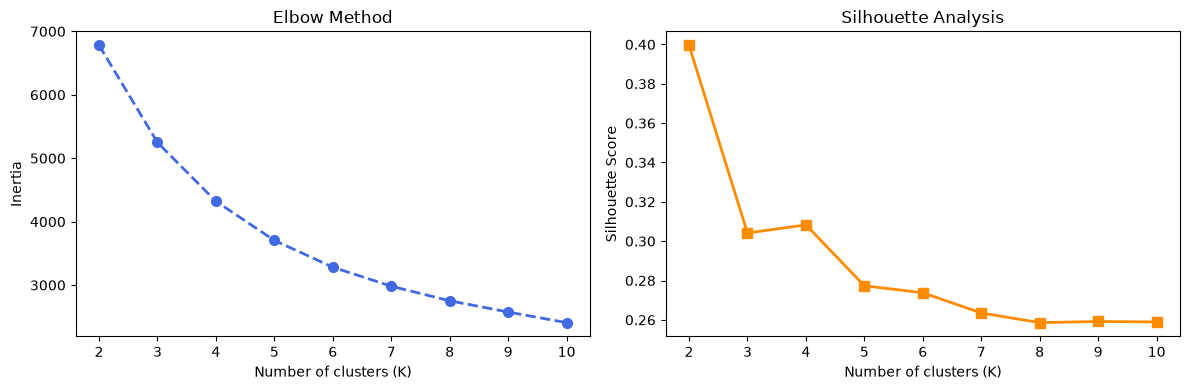

In [7]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler as Scaler
import matplotlib.pyplot as plt


feature_names = ["frequence", "recency", "montary"]
x_log = np.log1p(df_clients_rfm[feature_names])
X = Scaler().fit_transform(x_log)

def kmean():
    inertias = []
    sil_scores = []

    # Elbow can use K=1, but Silhouette needs K >= 2
    ks = range(2, 11)

    for k in ks:
        k_means = KMeans(
            n_clusters=k,
            init="k-means++",
            random_state=42,
            n_init=10
        )
        # fit(): set the centroids
        # predict(): predict the cluster label for each point in X
        labels = k_means.fit_predict(X) 

        # Inertia
        inertias.append(k_means.inertia_)

        # Silhouette Score
        # check if point existe in right cluster
        score = silhouette_score(X, labels) 
        sil_scores.append(score)
       

    # Create plots
    visualize_elbow_silhouette(ks, inertias, sil_scores)

def visualize_elbow_silhouette(ks, inertias, sil_scores):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        # Elbow
        axes[0].plot(
            ks,
            inertias,
            color="royalblue",
            marker="o",
            linestyle="--",
            linewidth=2,
            markersize=7
        )

        axes[0].set_xlabel("Number of clusters (K)")
        axes[0].set_ylabel("Inertia")
        axes[0].set_title("Elbow Method")

        # Silhouette
        axes[1].plot(
            ks,
            sil_scores,
            color="darkorange",
            marker="s",
            linestyle="-",
            linewidth=2,
            markersize=7
        )

        axes[1].set_xlabel("Number of clusters (K)")
        axes[1].set_ylabel("Silhouette Score")
        axes[1].set_title("Silhouette Analysis")

        plt.tight_layout()
        plt.show()


kmean()

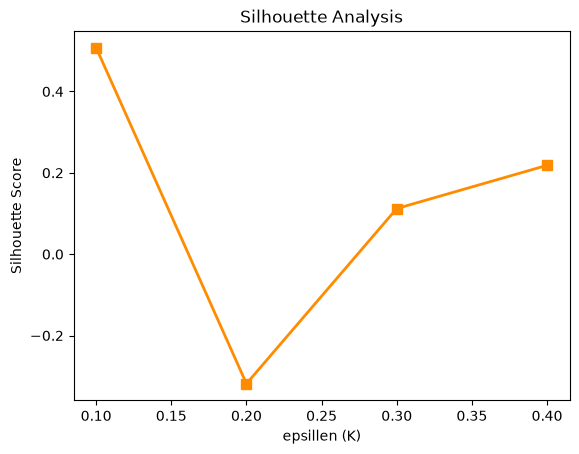

,eps,noise,labels_count,sil_score
0,0.1,97.416974,5,0.507655
1,0.2,41.328413,9,-0.318483
2,0.3,15.106089,4,0.112189
3,0.4,5.373616,2,0.218437


In [8]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
# import numpy as np

def dbscan(eps):
    db = DBSCAN(eps= eps, min_samples= 10)
    db.fit(X)
    return db

def choise_eps_silhouette():
    epsilons = [0.1, 0.2, 0.3, 0.4]
    sil_score = []
    labels_counts = []
    noises = []
    for eps in epsilons:
        db = dbscan(eps)
        labels = db.labels_
        
        _noise_labels_ = labels[labels == -1]
        valid_labels = labels[labels != -1]
        valid_X = X[labels != -1]
        
        _label_counts_ = len(set(valid_labels))
        
        if 2 <= _label_counts_ <= len(valid_X) - 1:
            score = silhouette_score(valid_X, valid_labels)
        else:
            score = np.nan
            
        noises.append((_noise_labels_.size *100 ) /labels.size )
        labels_counts.append(_label_counts_)
        sil_score.append(score)
        
    visualize_silhouette(epsilons, sil_score)   
    
    comparaison_data = pd.DataFrame({
        "eps": epsilons,
        "noise": noises,
        "labels_count": labels_counts,
        "sil_score": sil_score
    })  
    
    return comparaison_data;
    

def visualize_silhouette(ks, sil_scores):
    
        plt.plot(
            ks,
            sil_scores,
            color="darkorange",
            marker="s",
            linestyle="-",
            linewidth=2,
            markersize=7
        )

        plt.xlabel("epsillen (K)")
        plt.ylabel("Silhouette Score")
        plt.title("Silhouette Analysis")

        # plt.tight_layout()
        plt.show()

choise_eps_silhouette()
    

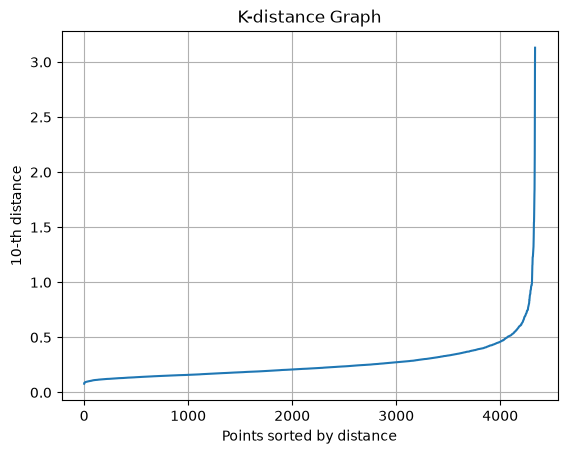

In [9]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

k = 10

neighbors = NearestNeighbors(n_neighbors=k)
neighbors.fit(X)

distances, _ = neighbors.kneighbors(X)

k_distances = distances[:, k - 1]

k_distances = np.sort(k_distances)

plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel("10-th distance")
plt.grid()
plt.title("K-distance Graph")
plt.show()

## <font color="green">Train model</font>

In [10]:
import numpy as np
import joblib

import datetime as dt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [26]:
feature_names = ["frequence", "recency", "montary"]



def get_labels()-> None:
    kmodel = Pipeline([
        ("log_transform", FunctionTransformer(np.log1p, validate=True)),
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=3, init="k-means++", random_state=42, n_init=10))
    ])

    X = df_clients_rfm[feature_names]
    labels_ = kmodel.fit_predict(X)

    df_clients_rfm["cluster"] = labels_
    
get_labels()

df_clients_rfm.head()


,ClientId,recency,frequence,montary,cluster,PC1,PC2
0,17850,372,297,5391.21,1,3339.293224,138.671978
1,13047,32,172,3237.54,2,1184.867555,73.349994
2,12583,3,247,7281.38,2,5229.315934,107.149340
3,13748,96,28,948.25,1,-1105.923473,-51.748232
4,15100,334,3,876.00,0,-1178.761496,-100.775836


In [12]:
def cross_validate_model(model, X_train, y_train):
    kfold = StratifiedKFold(
            n_splits=5,
            random_state=42,
            shuffle=True
        )
    
    scoring = {
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro"
        }
    
    cv_results = cross_validate(
            model,
            X_train,
            y_train,
            cv=kfold,
            scoring=scoring
        )
    print("Accuracy :", cv_results["test_accuracy"])
    print("Precision:", cv_results["test_precision"])
    print("Recall   :", cv_results["test_recall"])
    print("F1-score :", cv_results["test_f1"])

In [13]:
def train_model(X_train, y_train):
    
    rf_model = Pipeline([
        ("log_transform", FunctionTransformer(np.log1p, validate=True)),
        ("scaler", StandardScaler()),
        ("rf", RandomForestClassifier())
    ])
    
    cross_validate_model(rf_model, X_train, y_train)
    
    rf_model.fit(X_train, y_train)

    return rf_model    

In [14]:
X = df_clients_rfm[feature_names]
y = df_clients_rfm["cluster"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
model = train_model(X_train, y_train)

Accuracy : [0.9610951  0.96829971 0.98270893 0.97402597 0.96536797]
Precision: [0.96563011 0.96794472 0.98172079 0.97606342 0.96983923]
Recall   : [0.96107348 0.96794472 0.98222042 0.97366276 0.96415669]
F1-score : [0.96316196 0.96794472 0.98196123 0.97479121 0.96685469]


Accuracy : 0.9723502304147466
Precision: 0.9743690272420188
Recall   : 0.9721597391417637
F1-score : 0.9732417837688422


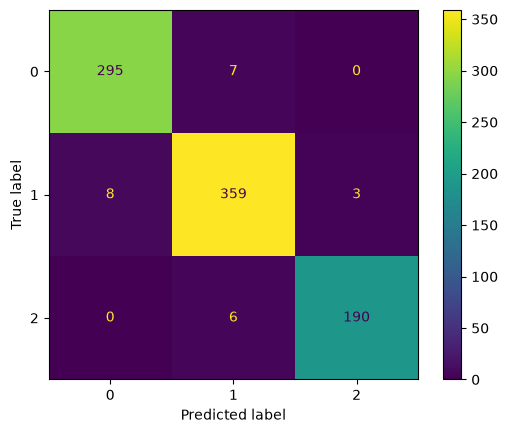

In [16]:


y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")


print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

cm=confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,)

disp.plot()


In [17]:
def predict_client(client_data):
    prediction = model.predict(client_data)
    cluster_label = prediction[0]
    name = "low" if cluster_label == 0 else "medium" if cluster_label == 1 else "high"
    print(f"Client belongs to the {name} cluster.")
    return prediction[0]

In [18]:
client_test = pd.DataFrame({
    "frequence": [5],
    "recency": [10],
    "montary": [100]
})

predict_client(client_test)

Client belongs to the low cluster.


np.int32(0)

In [19]:
def save_model(model, filename):
    filename = f"./model/{filename}_{dt.datetime.now().microsecond}.joblib"
    joblib.dump(model, filename)
    print(f"Model saved to {filename}")
    
    
save_model(model, "rf_model")    

Model saved to ./model/rf_model_315910.joblib


In [20]:
# import numpy as np

# def centroids_tabel():
#     r = np.expm1(scaler.inverse_transform(kmean.cluster_centers_))
#     cend_t= pd.DataFrame(r, index=["cluster 1", "cluster 2", "cluster 3"], columns= features).round(2)
#     return cend_t
        
# centroids_tabel()  

In [21]:

# def clusters_table():

#     cluster_groups = df_clients_rfm.groupby("cluster")

#     data = {
#         "Count": cluster_groups.size(),

#         "Mean Recency": cluster_groups["recency"].mean(),

#         "Mean Frequence": cluster_groups["frequence"].mean(),

#         "Mean Monetary": cluster_groups["montary"].mean(),
        
#         "Distribution": (cluster_groups["montary"].sum() /100 )* df_clients_rfm["montary"].sum(),

#         "Total Monetary": cluster_groups["montary"].sum()
#     }

#     df = pd.DataFrame(data)

#     df.index = [f"Cluster {i + 1}" for i in df.index]

#     return df

# clusters_table()



## <font color="green">PCA</font>

In [22]:
from sklearn.decomposition import PCA


pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

df_clients_rfm["PC1"] = X_pca[:, 0]
df_clients_rfm["PC2"] = X_pca[:, 1]

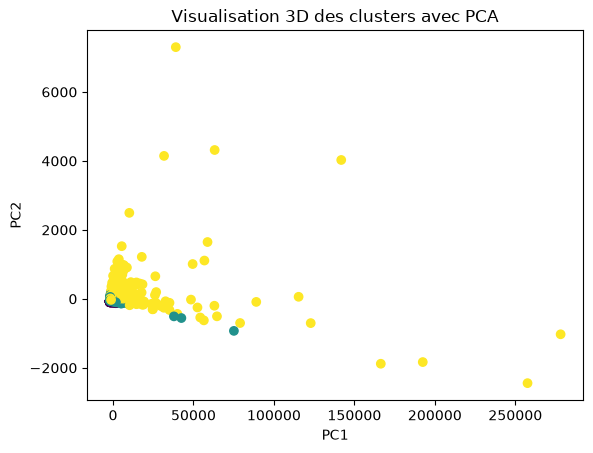

In [23]:
import matplotlib.pyplot as plt

plt.scatter(
    df_clients_rfm["PC1"],
    df_clients_rfm["PC2"],
    c=df_clients_rfm["cluster"],
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("Visualisation 3D des clusters avec PCA")

plt.show()

## Test code

Accuracy : 0.9723502304147466
Precision: 0.9743690272420188
Recall   : 0.9721597391417637


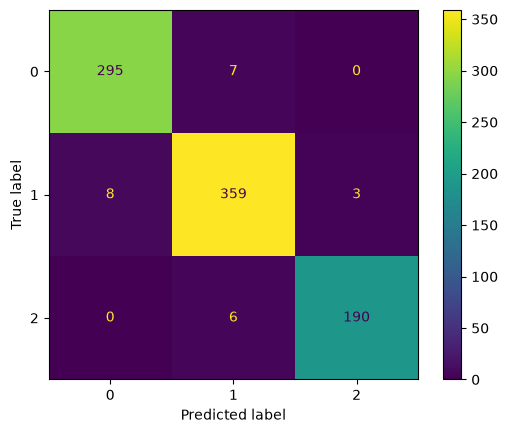

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,   
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)

cm=confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,)

disp.plot()